In [1]:
import warnings
warnings.filterwarnings("ignore")
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, precision_score,
                             recall_score, f1_score, fbeta_score, confusion_matrix)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42
SEEDS = [1, 7, 42, 123, 2024]
res = {}

In [2]:
df = pd.read_csv("treated2.csv")
ae = pd.read_csv("aeclean.csv")
print(df.shape, ae.shape)
print(ae["CTC_VERSION"].value_counts().to_dict())

DRUGS = {"bev": "Bevacizumab", "carbo": "Carboplatin", "pac": "Paclitaxel", "dox": "Doxorubicin", "cyclo": "Cyclophosphamide"}
BASE = ["AGE_C", "WHITE", "GRADE", "clinicalt", "clinicaln", "er", "pgr", "histotype", "meno", "her2fish", "her2ihc",
        "tsizepe", "tsizemamm", "tsizeultra", "tsizemri", "indrx", "factora", "factorb", "stra1_stage"]
CAT = ["indrx", "WHITE", "histotype", "GRADE", "clinicalt", "clinicaln", "meno", "er", "pgr", "her2ihc", "AGE_C", "stra1_stage"]

for c in ["GRADE", "clinicalt", "clinicaln"]:
    print(c, "code 9:", (df[c] == 9).sum())
    df[c] = df[c].replace(9, np.nan)

for d in DRUGS:
    df[d + "_label"] = ((df[d + "_ndelays"] > 0) | (df[d + "_nmods"] > 0)).astype(int)
    df.loc[df[d + "_received"] != 1, d + "_label"] = np.nan

miss = (df[BASE].isna().mean() * 100).round(1)
res["missing_pct"] = miss.to_dict()
print(miss.to_dict())

cohorts = pd.DataFrame([{"Drug": n, "n": int(df[d + "_label"].notna().sum()), "Positives": int(df[d + "_label"].sum()),
                         "Positive rate": round(df[d + "_label"].mean(), 3)} for d, n in DRUGS.items()])
res["cohorts"] = cohorts.to_dict("records")
print(cohorts)

both = df[df["dox_label"].notna() & df["cyclo_label"].notna()]
agree = int((both["dox_label"] == both["cyclo_label"]).sum())
res["dox_cyclo_agreement"] = {"n": len(both), "agree": agree}
print("dox/cyclo agree:", agree, "of", len(both), round(agree / len(both) * 100, 2))

(443, 61) (15435, 14)
{3: 15422, 9: 7, 2: 6}
GRADE code 9: 54
clinicalt code 9: 9
clinicaln code 9: 30
{'AGE_C': 0.0, 'WHITE': 0.0, 'GRADE': 12.2, 'clinicalt': 2.0, 'clinicaln': 6.8, 'er': 1.1, 'pgr': 1.6, 'histotype': 1.4, 'meno': 0.9, 'her2fish': 66.6, 'her2ihc': 15.8, 'tsizepe': 9.0, 'tsizemamm': 37.7, 'tsizeultra': 22.6, 'tsizemri': 31.2, 'indrx': 0.0, 'factora': 0.0, 'factorb': 0.0, 'stra1_stage': 0.0}
               Drug    n  Positives  Positive rate
0       Bevacizumab  219         98          0.447
1       Carboplatin  223         84          0.377
2        Paclitaxel  437        198          0.453
3       Doxorubicin  399        156          0.391
4  Cyclophosphamide  402        154          0.383
dox/cyclo agree: 397 of 398 99.75


In [3]:
WIN = {"pac": 7, "bev": 14, "carbo": 21, "dox": 98, "cyclo": 98}
TOP5 = {"Gastrointestinal": "gastrointestinal", "Blood/Bone Marrow": "blood_bone_marrow",
        "Constitutional Symptoms": "constitutional_symptoms", "Dermatology/Skin": "dermatology_skin", "Neurology": "neurology"}
ALL_CATS = {c: c.strip().lower().replace("/", "_").replace(" ", "_").replace(",", "") for c in ae["EVENTCAT"].value_counts().index}

w98 = ae[ae["aestart"].notna() & (ae["aestart"] <= 98)]
res["ae_window"] = {"negative_onset": int((ae["aestart"] < 0).sum()), "no_onset": int(ae["aestart"].isna().sum()),
                    "win98": len(w98), "before84": int((w98["aestart"] < 84).sum())}
print(res["ae_window"], round((w98["aestart"] < 84).mean() * 100, 1))

def ae_feats(days, d, cats=TOP5, min_rel=None, burden=False):
    e = ae[ae["aestart"].notna() & (ae["aestart"] <= days)]
    if min_rel is not None:
        e = e[e["RELATION_ID"] >= min_rel]
    f = e.groupby("MASK_ID").agg(**{"early_ae_count_" + d: ("EVENTNAME", "count"),
                                    "early_ae_max_grade_" + d: ("GRADE_ID", "max"),
                                    "early_ae_n_categories_" + d: ("EVENTCAT", "nunique")})
    for cat, s in cats.items():
        f["early_ae_" + s + "_" + d] = e[e["EVENTCAT"] == cat].groupby("MASK_ID")["EVENTNAME"].count()
    if burden:
        g = e.groupby("MASK_ID")["GRADE_ID"].sum()
        f["early_ae_burden_" + d] = g.reindex(f.index).fillna(0) * (1 + 0.1 * f["early_ae_n_categories_" + d])
    return f.fillna(0).reset_index()

def make_table(**kw):
    t = df.copy()
    for d, days in WIN.items():
        t = t.merge(ae_feats(days, d, **kw), on="MASK_ID", how="left")
    cols = [c for c in t.columns if c.startswith("early_ae_")]
    t[cols] = t[cols].fillna(0)
    return t

table = make_table()
print(table.shape)

{'negative_onset': 16, 'no_onset': 7, 'win98': 11287, 'before84': 8514} 75.4
(443, 106)


In [4]:
REG = {"base": (1.0, None, 1, 150, 2, 0.05), "mild": (0.5, 8, 3, 130, 2, 0.04), "strong": (0.01, 3, 10, 80, 1, 0.01)}
CANDS = {
    "LR C=1": dict(model="lr", C=1.0),
    "LR C=5": dict(model="lr", C=5.0),
    "Ens base": dict(model="ens", reg="base"),
    "Ens strong": dict(model="ens", reg="strong"),
    "Ens base+SMOTE": dict(model="ens", reg="base", smote=True),
    "Ens mild+SMOTE": dict(model="ens", reg="mild", smote=True),
    "Ens base, fewer AE": dict(model="ens", reg="base", fewer=True),
}
FIXED = {"bev": "LR C=5", "carbo": "Ens base+SMOTE", "pac": "Ens strong", "dox": "Ens base, fewer AE", "cyclo": "Ens mild+SMOTE"}

def cfg_of(d, **ch):
    c = dict(CANDS[FIXED[d]])
    c.update(ch)
    return c

def get_model(c, seed):
    if "est" in c:
        return c["est"](seed)
    if c["model"] == "lr":
        return LogisticRegression(max_iter=1000, class_weight="balanced", C=c.get("C", 1.0))
    C, depth, leaf, n, gdepth, lr = REG[c["reg"]]
    est = [("lr", LogisticRegression(max_iter=1000, class_weight="balanced", C=C)),
           ("rf", RandomForestClassifier(n_estimators=300, max_depth=depth, min_samples_leaf=leaf, class_weight="balanced", random_state=seed)),
           ("gb", GradientBoostingClassifier(n_estimators=n, max_depth=gdepth, learning_rate=lr, random_state=seed))]
    if c.get("no_gb"):
        est = est[:2]
    return VotingClassifier(est, voting=c.get("voting", "soft"), weights=c.get("weights"))

def get_feats(d, c, t):
    cols = [x for x in t.columns if x.startswith("early_ae_") and x.endswith("_" + d)]
    if c.get("fewer"):
        cols = [x for x in cols if x.startswith(("early_ae_count_", "early_ae_max_grade_", "early_ae_n_categories_", "early_ae_burden_"))]
    return BASE + cols + c.get("extra", [])

def get_pipe(feats, c, seed=RANDOM_STATE):
    num = [f for f in feats if f not in CAT]
    cat = [f for f in feats if f in CAT]
    scaler = StandardScaler() if c.get("scaler") == "standard" else RobustScaler()
    ct = [("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", scaler)]), num)]
    if cat:
        ct.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                    ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat))
    steps = [("pre", ColumnTransformer(ct))]
    if c.get("step") is not None:
        steps.append(("step", clone(c["step"])))
    if c.get("smote"):
        steps.append(("smote", SMOTE(random_state=seed, k_neighbors=5)))
    steps.append(("model", get_model(c, seed)))
    return ImbPipeline(steps)

In [5]:
GRID = np.arange(0.15, 0.56, 0.01)
METRICS = ["AUC", "PR-AUC", "Precision", "Recall", "F1", "F2", "Specificity", "Brier"]

def best_thr(y, p):
    bt, bs = 0.5, -1
    for t in GRID:
        s = fbeta_score(y, (p >= t).astype(int), beta=2, zero_division=0)
        if s > bs:
            bt, bs = t, s
    return bt

def scores(y, p, yhat):
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    return {"AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "Precision": precision_score(y, yhat, zero_division=0), "Recall": recall_score(y, yhat, zero_division=0),
            "F1": f1_score(y, yhat, zero_division=0), "F2": fbeta_score(y, yhat, beta=2, zero_division=0),
            "Specificity": tn / (tn + fp), "Brier": brier_score_loss(y, p)}

memo = {}

def run_cv(d, c=None, seed=RANDOM_STATE, t=None, tname="main"):
    c = CANDS[FIXED[d]] if c is None else c
    key = (d, repr(sorted((k, repr(v)) for k, v in c.items())), seed, tname)
    if key in memo:
        return memo[key]
    t = table if t is None else t
    data = t[t[d + "_label"].notna()]
    feats = get_feats(d, c, data)
    X, y = data[feats], data[d + "_label"].astype(int)
    idx, ys, ps, preds = [], [], [], []
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y):
        inner = StratifiedKFold(4, shuffle=True, random_state=seed)
        pin = cross_val_predict(get_pipe(feats, c, seed), X.iloc[tr], y.iloc[tr], cv=inner, method="predict_proba")[:, 1]
        thr = best_thr(y.iloc[tr], pin)
        p = get_pipe(feats, c, seed).fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[te])[:, 1]
        idx += list(X.index[te]); ys += y.iloc[te].tolist(); ps += p.tolist(); preds += (p >= thr).astype(int).tolist()
    out = scores(np.array(ys), np.array(ps), np.array(preds))
    out.update(idx=np.array(idx), y=np.array(ys), p=np.array(ps), pred=np.array(preds), n=len(y))
    memo[key] = out
    return out

def full_nested(d, seed):
    data = table[table[d + "_label"].notna()]
    y = data[d + "_label"].astype(int)
    idx, ys, ps, preds, chosen, thrs = [], [], [], [], [], []
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=seed).split(data, y):
        inner = StratifiedKFold(4, shuffle=True, random_state=seed)
        best = None
        for name, c in CANDS.items():
            feats = get_feats(d, c, data)
            pin = cross_val_predict(get_pipe(feats, c, seed), data.iloc[tr][feats], y.iloc[tr], cv=inner, method="predict_proba")[:, 1]
            auc = roc_auc_score(y.iloc[tr], pin)
            if best is None or auc > best[1]:
                best = (name, auc, pin, feats, c)
        name, auc, pin, feats, c = best
        thr = best_thr(y.iloc[tr], pin)
        p = get_pipe(feats, c, seed).fit(data.iloc[tr][feats], y.iloc[tr]).predict_proba(data.iloc[te][feats])[:, 1]
        idx += list(data.index[te]); ys += y.iloc[te].tolist(); ps += p.tolist(); preds += (p >= thr).astype(int).tolist()
        chosen.append(name)
        thrs.append(round(float(thr), 2))
    out = scores(np.array(ys), np.array(ps), np.array(preds))
    out.update(idx=np.array(idx), y=np.array(ys), p=np.array(ps), pred=np.array(preds), n=len(y), chosen=chosen, thr=thrs, d=d, seed=seed)
    return out

def boot_ci(y, p, f, n=2000):
    rng = np.random.default_rng(RANDOM_STATE)
    v = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            v.append(f(y[i], p[i]))
    return np.percentile(v, [2.5, 97.5])

def msd(v):
    v = np.asarray(v, dtype=float)
    return f"{v.mean():.3f} ± {v.std(ddof=1):.3f}"

In [6]:
out = Parallel(n_jobs=2)(delayed(full_nested)(d, s) for d in DRUGS for s in SEEDS)
FN = {(r["d"], r["seed"]): r for r in out}

In [7]:
rows = []
for d, name in DRUGS.items():
    runs = [FN[(d, s)] for s in SEEDS]
    r = FN[(d, 42)]
    pos = r["y"].mean()
    flag = 5 * pos / (4 * pos + 1)
    a = boot_ci(r["y"], r["p"], roc_auc_score)
    b = boot_ci(r["y"], r["p"], average_precision_score)
    row = {"Drug": name, "n": r["n"], "Positive rate": round(pos, 3)}
    row.update({m: msd([x[m] for x in runs]) for m in METRICS})
    row.update({"AUC 95% CI (seed 42)": f"{a[0]:.3f}-{a[1]:.3f}", "PR-AUC 95% CI (seed 42)": f"{b[0]:.3f}-{b[1]:.3f}",
                "F2 flag-all": round(flag, 3), "Seeds F2 > flag-all": sum(x["F2"] > flag for x in runs), "AUC CI includes 0.5": a[0] <= 0.5})
    rows.append(row)
table2 = pd.DataFrame(rows)
res["table2_fully_nested"] = table2.to_dict("records")
table2.to_csv("Table_II_fully_nested.csv", index=False)
table2

,Drug,n,Positive rate,AUC,PR-AUC,Precision,Recall,F1,F2,Specificity,Brier,AUC 95% CI (seed 42),PR-AUC 95% CI (seed 42),F2 flag-all,Seeds F2 > flag-all,AUC CI includes 0.5
0,Bevacizumab,219,0.447,0.555 ± 0.030,0.481 ± 0.013,0.470 ± 0.007,0.971 ± 0.015,0.633 ± 0.009,0.801 ± 0.012,0.112 ± 0.015,0.272 ± 0.010,0.434-0.586,0.389-0.575,0.802,3,True
1,Carboplatin,223,0.377,0.663 ± 0.023,0.538 ± 0.041,0.376 ± 0.005,0.974 ± 0.035,0.542 ± 0.010,0.738 ± 0.020,0.022 ± 0.023,0.225 ± 0.005,0.599-0.755,0.481-0.694,0.751,1,False
2,Paclitaxel,437,0.453,0.681 ± 0.009,0.607 ± 0.016,0.466 ± 0.004,0.966 ± 0.014,0.629 ± 0.004,0.795 ± 0.008,0.085 ± 0.021,0.229 ± 0.003,0.624-0.727,0.531-0.680,0.806,1,False
3,Doxorubicin,399,0.391,0.708 ± 0.012,0.580 ± 0.019,0.432 ± 0.019,0.958 ± 0.010,0.595 ± 0.018,0.770 ± 0.011,0.190 ± 0.066,0.212 ± 0.004,0.677-0.774,0.533-0.689,0.762,4,False
4,Cyclophosphamide,402,0.383,0.700 ± 0.013,0.558 ± 0.017,0.439 ± 0.010,0.943 ± 0.008,0.599 ± 0.010,0.767 ± 0.009,0.250 ± 0.031,0.215 ± 0.004,0.626-0.729,0.457-0.621,0.756,4,False


In [8]:
rows = []
for d, name in DRUGS.items():
    runs = [FN[(d, s)] for s in SEEDS]
    oof = pd.concat([pd.DataFrame({"idx": r["idx"], "y": r["y"], "p": r["p"]}) for r in runs])
    avg = oof.groupby("idx").agg(y=("y", "first"), p=("p", "mean"))
    y, p = avg["y"].values, avg["p"].values
    a = boot_ci(y, p, roc_auc_score)
    b = boot_ci(y, p, average_precision_score)
    rows.append({"Drug": name, "AUC (seed-averaged probabilities)": round(roc_auc_score(y, p), 3),
                 "AUC 95% CI": f"{a[0]:.3f}-{a[1]:.3f}", "PR-AUC 95% CI": f"{b[0]:.3f}-{b[1]:.3f}",
                 "AUC seed 42": round(FN[(d, 42)]["AUC"], 3)})
ci_avg = pd.DataFrame(rows)
res["ci_seed_averaged"] = ci_avg.to_dict("records")
ci_avg

,Drug,AUC (seed-averaged probabilities),AUC 95% CI,PR-AUC 95% CI,AUC seed 42
0,Bevacizumab,0.566,0.490-0.637,0.399-0.581,0.509
1,Carboplatin,0.669,0.591-0.747,0.449-0.672,0.677
2,Paclitaxel,0.690,0.639-0.738,0.549-0.693,0.677
3,Doxorubicin,0.720,0.669-0.769,0.516-0.676,0.727
4,Cyclophosphamide,0.715,0.665-0.767,0.494-0.660,0.680


In [9]:
by_seed = pd.DataFrame([{"Drug": DRUGS[d], "Seed": s, **{m: round(FN[(d, s)][m], 3) for m in METRICS}} for d in DRUGS for s in SEEDS])
res["fully_nested_by_seed"] = by_seed.to_dict("records")
by_seed.to_csv("Table_S1_fully_nested_by_seed.csv", index=False)
print(by_seed)

counts = pd.DataFrame([{"Drug": DRUGS[d], "chosen": c} for d in DRUGS for s in SEEDS for c in FN[(d, s)]["chosen"]])
counts = counts.groupby(["Drug", "chosen"]).size().unstack(fill_value=0)
res["chosen_counts"] = {k: {kk: int(vv) for kk, vv in v.items()} for k, v in counts.T.to_dict().items()}
counts

                Drug  Seed    AUC  PR-AUC  Precision  Recall     F1     F2  Specificity  Brier
0        Bevacizumab     1  0.561   0.481      0.473   0.990  0.640  0.812        0.107  0.258
1        Bevacizumab     7  0.581   0.499      0.473   0.980  0.638  0.807        0.116  0.268
2        Bevacizumab    42  0.509   0.473      0.458   0.949  0.618  0.782        0.091  0.282
3        Bevacizumab   123  0.544   0.465      0.475   0.969  0.638  0.802        0.132  0.283
4        Bevacizumab  2024  0.581   0.489      0.470   0.969  0.633  0.800        0.116  0.270
5        Carboplatin     1  0.640   0.480      0.380   1.000  0.551  0.754        0.014  0.230
6        Carboplatin     7  0.683   0.562      0.370   0.964  0.535  0.730        0.007  0.222
7        Carboplatin    42  0.677   0.583      0.381   0.988  0.550  0.749        0.029  0.219
8        Carboplatin   123  0.637   0.512      0.370   0.917  0.527  0.708        0.058  0.232
9        Carboplatin  2024  0.679   0.555      0.3

chosen,Ens base+SMOTE,"Ens base, fewer AE",Ens mild+SMOTE,Ens strong,LR C=1,LR C=5
Drug,,,,,,
Bevacizumab,0,0,1,5,11,8
Carboplatin,1,2,4,18,0,0
Cyclophosphamide,0,13,0,11,1,0
Doxorubicin,1,17,1,6,0,0
Paclitaxel,0,1,7,15,1,1


In [10]:
rows = []
for d, name in DRUGS.items():
    fx = [run_cv(d, seed=s) for s in SEEDS]
    fn = [FN[(d, s)] for s in SEEDS]
    rows.append({"Drug": name, "AUC fixed": msd([r["AUC"] for r in fx]), "Recall fixed": msd([r["Recall"] for r in fx]),
                 "Specificity fixed": msd([r["Specificity"] for r in fx]), "AUC fully nested": msd([r["AUC"] for r in fn]),
                 "Optimism (mean AUC)": round(np.mean([r["AUC"] for r in fx]) - np.mean([r["AUC"] for r in fn]), 3),
                 "AUC fixed, seed 42": round(fx[2]["AUC"], 3), "AUC fully nested, seed 42": round(fn[2]["AUC"], 3)})
opt = pd.DataFrame(rows)
res["fixed_vs_nested"] = opt.to_dict("records")
fixed = {d: run_cv(d) for d in DRUGS}
opt

,Drug,AUC fixed,Recall fixed,Specificity fixed,AUC fully nested,Optimism (mean AUC),"AUC fixed, seed 42","AUC fully nested, seed 42"
0,Bevacizumab,0.560 ± 0.017,0.941 ± 0.015,0.154 ± 0.020,0.555 ± 0.030,0.005,0.538,0.509
1,Carboplatin,0.664 ± 0.017,0.910 ± 0.047,0.105 ± 0.046,0.663 ± 0.023,0.001,0.674,0.677
2,Paclitaxel,0.699 ± 0.004,0.979 ± 0.011,0.059 ± 0.017,0.681 ± 0.009,0.018,0.698,0.677
3,Doxorubicin,0.720 ± 0.009,0.963 ± 0.005,0.186 ± 0.034,0.708 ± 0.012,0.012,0.734,0.727
4,Cyclophosphamide,0.713 ± 0.007,0.956 ± 0.018,0.217 ± 0.042,0.700 ± 0.013,0.013,0.719,0.680


In [11]:
rng = np.random.default_rng(RANDOM_STATE)
perm_t = table.copy()
for d in DRUGS:
    m = perm_t[d + "_label"].notna()
    perm_t.loc[m, d + "_label"] = rng.permutation(perm_t.loc[m, d + "_label"].values)
perm = pd.DataFrame([{"Drug": n, **{m: round(run_cv(d, t=perm_t, tname="perm")[m], 3) for m in ["AUC", "Recall", "Specificity", "F2"]}}
                     for d, n in DRUGS.items()])
res["permuted"] = perm.to_dict("records")
perm

,Drug,AUC,Recall,Specificity,F2
0,Bevacizumab,0.374,0.908,0.033,0.744
1,Carboplatin,0.568,0.976,0.043,0.744
2,Paclitaxel,0.550,1.000,0.000,0.806
3,Doxorubicin,0.473,0.994,0.000,0.758
4,Cyclophosphamide,0.479,0.994,0.000,0.752


In [12]:
def perm_run(d, k):
    t = table.copy()
    m = t[d + "_label"].notna()
    t.loc[m, d + "_label"] = np.random.default_rng(k).permutation(t.loc[m, d + "_label"].values)
    r = run_cv(d, t=t, tname="perm%d" % k)
    return d, k, r["AUC"], r["Recall"]

pr = Parallel(n_jobs=2)(delayed(perm_run)(d, k) for d in DRUGS for k in range(20))
pr = pd.DataFrame(pr, columns=["d", "k", "AUC", "Recall"])
rows = []
for d, name in DRUGS.items():
    g = pr[pr["d"] == d]
    real = fixed[d]["AUC"]
    rows.append({"Drug": name, "Fixed AUC (seed 42)": round(real, 3), "Permuted AUC mean": round(g["AUC"].mean(), 3),
                 "Permuted AUC min": round(g["AUC"].min(), 3), "Permuted AUC max": round(g["AUC"].max(), 3),
                 "Permuted recall mean": round(g["Recall"].mean(), 3), "p": round((1 + (g["AUC"] >= real).sum()) / 21, 3)})
perm20 = pd.DataFrame(rows)
res["permuted20"] = perm20.to_dict("records")
perm20

,Drug,Fixed AUC (seed 42),Permuted AUC mean,Permuted AUC min,Permuted AUC max,Permuted recall mean,p
0,Bevacizumab,0.538,0.488,0.382,0.621,0.916,0.190
1,Carboplatin,0.674,0.490,0.368,0.629,0.973,0.048
2,Paclitaxel,0.698,0.504,0.436,0.569,0.999,0.048
3,Doxorubicin,0.734,0.492,0.442,0.559,0.996,0.048
4,Cyclophosphamide,0.719,0.500,0.426,0.567,0.995,0.048


In [13]:
rows = []
for d, name in DRUGS.items():
    r = FN[(d, 42)]
    for t in [0.2, 0.3, 0.4, 0.5]:
        tn, fp, fn, tp = confusion_matrix(r["y"], (r["p"] >= t).astype(int), labels=[0, 1]).ravel()
        rows.append({"Drug": name, "Threshold": t, "Recall": round(tp / (tp + fn), 3), "Specificity": round(tn / (tn + fp), 3)})
thr = pd.DataFrame(rows)
res["threshold"] = thr.to_dict("records")
ths = {DRUGS[d]: FN[(d, 42)]["thr"] for d in DRUGS}
allt = [x for v in ths.values() for x in v]
res["f2_thresholds_seed42"] = ths
print(ths)
print("range", min(allt), "-", max(allt), "| in 0.15-0.25:", sum(0.15 <= x <= 0.25 for x in allt), "of", len(allt))
print(thr[thr["Threshold"] == 0.4])

def calib(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    lp = np.log(p / (1 - p))
    slope = sm.GLM(y, sm.add_constant(lp), family=sm.families.Binomial()).fit().params[1]
    inter = sm.GLM(y, np.ones_like(lp), family=sm.families.Binomial(), offset=lp).fit().params[0]
    return slope, inter

rows = []
for d, name in DRUGS.items():
    sl, ic = zip(*[calib(FN[(d, s)]["y"], FN[(d, s)]["p"]) for s in SEEDS])
    pos = FN[(d, 42)]["y"].mean()
    rows.append({"Drug": name, "Calibration slope": msd(sl), "Slope min": round(min(sl), 3), "Slope max": round(max(sl), 3),
                 "Calibration intercept": msd(ic),
                 "Brier": msd([FN[(d, s)]["Brier"] for s in SEEDS]), "Brier, constant p": round(pos * (1 - pos), 3)})
cal = pd.DataFrame(rows)
res["calibration"] = cal.to_dict("records")
cal

{'Bevacizumab': [0.18, 0.15, 0.15, 0.15, 0.37], 'Carboplatin': [0.15, 0.31, 0.15, 0.15, 0.15], 'Paclitaxel': [0.38, 0.36, 0.35, 0.22, 0.15], 'Doxorubicin': [0.2, 0.39, 0.16, 0.22, 0.24], 'Cyclophosphamide': [0.25, 0.18, 0.16, 0.3, 0.4]}
range 0.15 - 0.4 | in 0.15-0.25: 17 of 25
                Drug  Threshold  Recall  Specificity
2        Bevacizumab        0.4   0.714        0.281
6        Carboplatin        0.4   0.726        0.540
10        Paclitaxel        0.4   0.854        0.397
14       Doxorubicin        0.4   0.814        0.556
18  Cyclophosphamide        0.4   0.786        0.508


,Drug,Calibration slope,Slope min,Slope max,Calibration intercept,Brier,"Brier, constant p"
0,Bevacizumab,0.211 ± 0.086,0.088,0.297,-0.187 ± 0.038,0.272 ± 0.010,0.247
1,Carboplatin,1.179 ± 0.594,0.625,2.144,-0.296 ± 0.016,0.225 ± 0.005,0.235
2,Paclitaxel,0.955 ± 0.285,0.676,1.307,-0.126 ± 0.032,0.229 ± 0.003,0.248
3,Doxorubicin,0.966 ± 0.078,0.894,1.092,-0.228 ± 0.017,0.212 ± 0.004,0.238
4,Cyclophosphamide,1.025 ± 0.218,0.721,1.311,-0.273 ± 0.012,0.215 ± 0.004,0.236


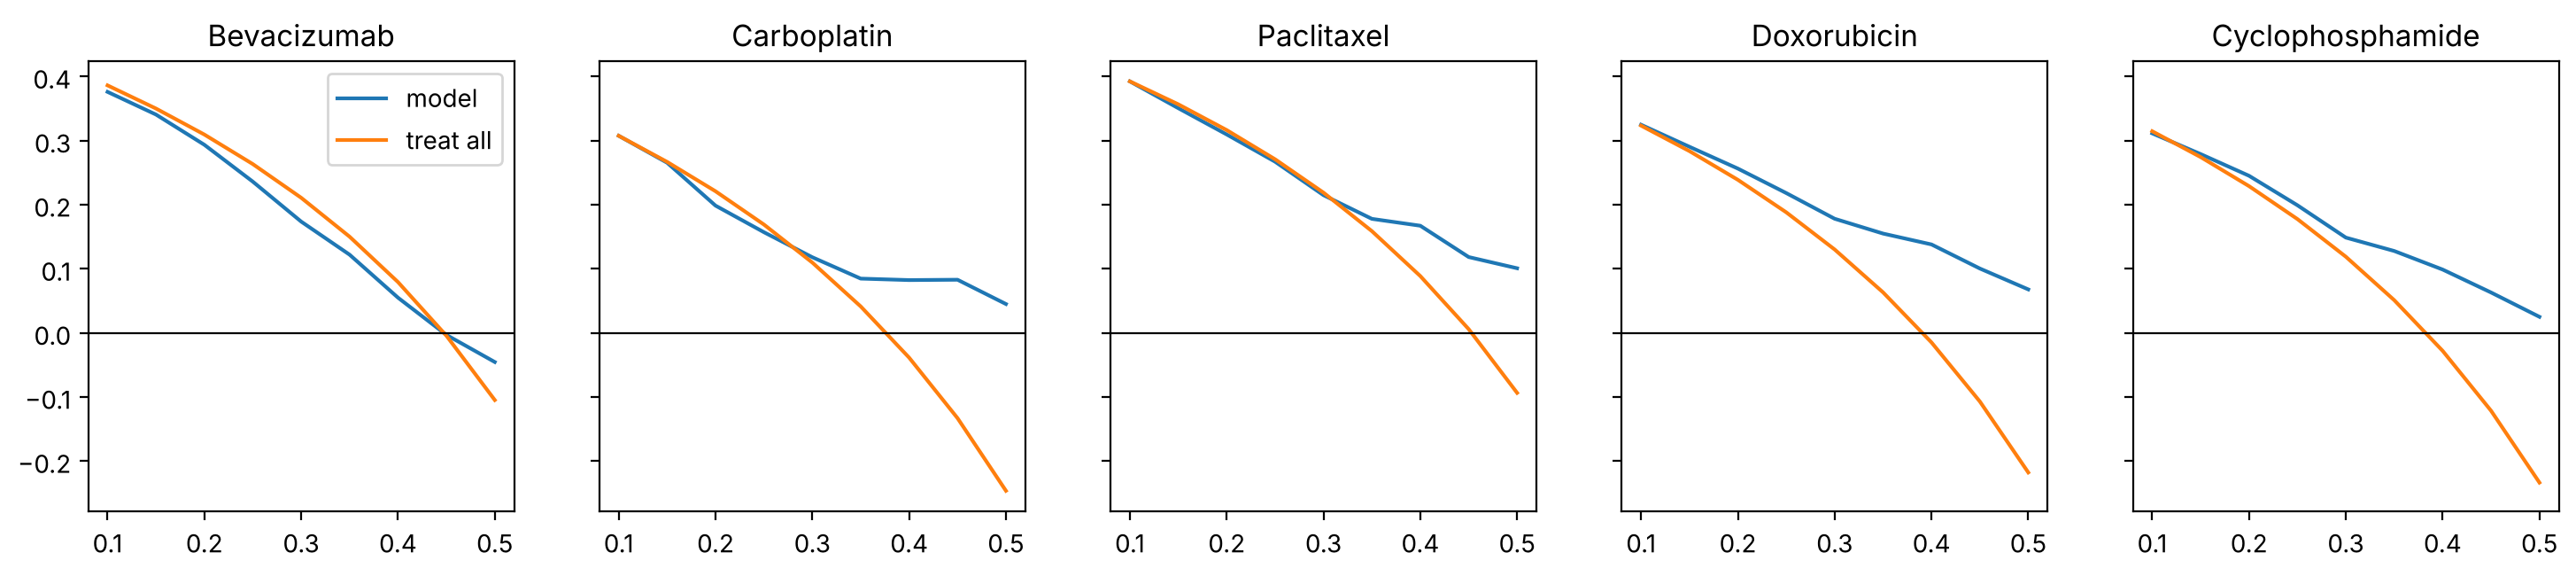

Drug       Bevacizumab  Carboplatin  Cyclophosphamide  Doxorubicin  Paclitaxel
Threshold                                                                     
0.15           -0.0094      -0.0013            0.0047       0.0068     -0.0061
0.20           -0.0160      -0.0225            0.0161       0.0176     -0.0069
0.25           -0.0274      -0.0119            0.0216       0.0300     -0.0038


,Drug,Thresholds where model > treat-all and > 0
0,Bevacizumab,[]
1,Carboplatin,"[0.3, 0.35, 0.4, 0.45, 0.5]"
2,Paclitaxel,"[0.35, 0.4, 0.45, 0.5]"
3,Doxorubicin,"[0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]"
4,Cyclophosphamide,"[0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]"


In [14]:
PT = np.round(np.arange(0.10, 0.51, 0.05), 2)
rows, summ = [], []
fig, axes = plt.subplots(1, 5, figsize=(18, 3.3), sharey=True)
for ax, (d, name) in zip(axes, DRUGS.items()):
    y, p = FN[(d, 42)]["y"], FN[(d, 42)]["p"]
    prev = y.mean()
    nb = [((p >= t) & (y == 1)).sum() / len(y) - ((p >= t) & (y == 0)).sum() / len(y) * t / (1 - t) for t in PT]
    nb_all = [prev - (1 - prev) * t / (1 - t) for t in PT]
    for t, a, b in zip(PT, nb, nb_all):
        rows.append({"Drug": name, "Threshold": t, "NB model": round(a, 4), "NB treat-all": round(b, 4), "NB treat-none": 0.0})
    summ.append({"Drug": name, "Thresholds where model > treat-all and > 0": [float(t) for t, a, b in zip(PT, nb, nb_all) if a > max(b, 0)]})
    ax.plot(PT, nb, label="model"); ax.plot(PT, nb_all, label="treat all"); ax.axhline(0, c="k", lw=0.8)
    ax.set_title(name)
axes[0].legend()
plt.show()
res["dca"] = rows
res["dca_summary"] = summ
dc = pd.DataFrame(rows)
dc["NB model - treat-all"] = (dc["NB model"] - dc["NB treat-all"]).round(4)
nb_low = dc[dc["Threshold"].isin([0.15, 0.2, 0.25])].pivot(index="Threshold", columns="Drug", values="NB model - treat-all")
res["nb_minus_all_low"] = nb_low.reset_index().to_dict("records")
print(nb_low)
pd.DataFrame(summ)

In [15]:
SUB = {"AGE_C": "Age group", "WHITE": "Race", "GRADE": "Grade", "clinicalt": "Clinical T", "meno": "Menopausal status", "histotype": "Histology"}
LEV = {"AGE_C": {1: "<40", 2: "40-59", 3: ">=60"}, "WHITE": {1: "White", 2: "Non-White"}, "GRADE": {1: "Low", 2: "Intermediate", 3: "High"},
       "clinicalt": {1: "T1", 2: "T2", 3: "T3", 4: "T4"}, "meno": {0: "Pre", 1: "Post"},
       "histotype": {1: "Ductal", 2: "Lobular", 3: "Invasive mammary NOS", 4: "Mixed ductal & lobular", 5: "Other"}}
rows = []
for d, name in DRUGS.items():
    r = FN[(d, 42)]
    s = table.loc[r["idx"]].copy()
    s["y"], s["pred"], s["p"] = r["y"], r["pred"], r["p"]
    overall = recall_score(s["y"], s["pred"])
    for v, lab in SUB.items():
        for lev, g in s.groupby(v):
            if g["y"].sum() == 0:
                continue
            auc = roc_auc_score(g["y"], g["p"]) if g["y"].nunique() == 2 else np.nan
            rec = recall_score(g["y"], g["pred"])
            rows.append({"Drug": name, "Variable": lab, "Level": LEV[v].get(lev, lev), "n": len(g), "Recall": round(rec, 3),
                         "Drop (pp)": round(100 * (overall - rec), 1), "AUC": round(auc, 3)})
sg = pd.DataFrame(rows)
big = sg[sg["n"] >= 10]
small = sg[(sg["n"] < 10) & (sg["Drop (pp)"] >= 15)]
res["subgroups"] = {"n_combos": len(sg), "n_flagged": int((big["Drop (pp)"] >= 15).sum()),
                    "largest_drop": big.sort_values("Drop (pp)", ascending=False).head(3).to_dict("records"),
                    "auc_min": float(big["AUC"].min()), "auc_max": float(big["AUC"].max()), "small_large_drops": small.to_dict("records")}
print(len(sg), "combos,", (big["Drop (pp)"] >= 15).sum(), "flagged, AUC", big["AUC"].min(), "-", big["AUC"].max())
print(big.sort_values("Drop (pp)", ascending=False).head(3))
small

93 combos, 0 flagged, AUC 0.226 - 0.875
                Drug    Variable                 Level   n  Recall  Drop (pp)    AUC
0        Bevacizumab   Age group                   <40  57   0.812       13.6  0.416
47        Paclitaxel  Clinical T                    T4  10   0.875        9.0  0.500
90  Cyclophosphamide   Histology  Invasive mammary NOS  16   0.875        8.0  0.703


,Drug,Variable,Level,n,Recall,Drop (pp),AUC
17,Bevacizumab,Histology,Other,6,0.333,61.6,0.000
72,Doxorubicin,Histology,Mixed ductal & lobular,8,0.667,28.8,0.467
85,Cyclophosphamide,Clinical T,T4,7,0.714,24.0,NaN
91,Cyclophosphamide,Histology,Mixed ductal & lobular,8,0.667,28.8,0.667


In [16]:
rows = []
for d, name in DRUGS.items():
    c = CANDS[FIXED[d]]
    data = table[table[d + "_label"].notna()]
    feats = get_feats(d, c, data)
    X, y = data[feats], data[d + "_label"].astype(int)
    imp = []
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(X, y):
        m = get_pipe(feats, c).fit(X.iloc[tr], y.iloc[tr])
        imp.append(permutation_importance(m, X.iloc[te], y.iloc[te], scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE).importances_mean)
    imp = np.mean(imp, axis=0)
    for rank, k in enumerate(np.argsort(-imp)[:3], 1):
        rows.append({"Drug": name, "Rank": rank, "Feature": feats[k], "AUC drop": round(imp[k], 4)})
imp_t = pd.DataFrame(rows)
res["importance"] = imp_t.to_dict("records")
print(imp_t)

rows = []
for d, name in DRUGS.items():
    r = fixed[d]
    s = table.loc[r["idx"]]
    fp = (r["pred"] == 1) & (r["y"] == 0)
    tn = (r["pred"] == 0) & (r["y"] == 0)
    for f in ["early_ae_count", "early_ae_max_grade"]:
        a, b = s[f + "_" + d].values[fp], s[f + "_" + d].values[tn]
        rows.append({"Drug": name, "Feature": f, "FP mean": round(a.mean(), 2), "TN mean": round(b.mean(), 2), "n FP": len(a), "n TN": len(b)})
fpd = pd.DataFrame(rows)
res["fp_descriptive"] = fpd.to_dict("records")
fpd

                Drug  Rank                           Feature  AUC drop
0        Bevacizumab     1            early_ae_max_grade_bev    0.0618
1        Bevacizumab     2                early_ae_count_bev    0.0501
2        Bevacizumab     3                             AGE_C    0.0186
3        Carboplatin     1          early_ae_max_grade_carbo    0.1245
4        Carboplatin     2  early_ae_blood_bone_marrow_carbo    0.0277
5        Carboplatin     3                           her2ihc    0.0150
6         Paclitaxel     1                           factora    0.0499
7         Paclitaxel     2                             indrx    0.0276
8         Paclitaxel     3    early_ae_blood_bone_marrow_pac    0.0097
9        Doxorubicin     1            early_ae_max_grade_dox    0.0578
10       Doxorubicin     2                early_ae_count_dox    0.0342
11       Doxorubicin     3                         clinicalt    0.0255
12  Cyclophosphamide     1          early_ae_max_grade_cyclo    0.1018
13  Cy

,Drug,Feature,FP mean,TN mean,n FP,n TN
0,Bevacizumab,early_ae_count,9.24,9.05,100,21
1,Bevacizumab,early_ae_max_grade,2.00,1.62,100,21
2,Carboplatin,early_ae_count,9.65,5.89,130,9
3,Carboplatin,early_ae_max_grade,1.95,1.22,130,9
4,Paclitaxel,early_ae_count,5.87,2.93,225,14
5,Paclitaxel,early_ae_max_grade,1.30,0.86,225,14
6,Doxorubicin,early_ae_count,25.07,17.79,195,48
7,Doxorubicin,early_ae_max_grade,2.73,1.92,195,48
8,Cyclophosphamide,early_ae_count,26.01,17.49,180,68
9,Cyclophosphamide,early_ae_max_grade,2.82,1.91,180,68


In [17]:
lr1, ens = CANDS["LR C=1"], CANDS["Ens base"]
CHOICES = [
    ("bev", "LR instead of ensemble", ens, lr1, "AUC"),
    ("bev", "C = 5 instead of C = 1", lr1, CANDS["LR C=5"], "AUC"),
    ("carbo", "Ensemble instead of LR", lr1, ens, "AUC"),
    ("carbo", "SMOTE", ens, CANDS["Ens base+SMOTE"], "Specificity"),
    ("pac", "Ensemble (strong) instead of LR", lr1, CANDS["Ens strong"], "AUC"),
    ("pac", "Strong regularization", ens, CANDS["Ens strong"], "AUC"),
    ("dox", "Ensemble instead of LR", lr1, ens, "AUC"),
    ("dox", "Fewer AE features", ens, CANDS["Ens base, fewer AE"], "AUC"),
    ("cyclo", "Ensemble instead of LR", lr1, ens, "AUC"),
    ("cyclo", "Mild regularization (with SMOTE)", CANDS["Ens base+SMOTE"], CANDS["Ens mild+SMOTE"], "Specificity"),
    ("cyclo", "SMOTE (with mild regularization)", dict(CANDS["Ens mild+SMOTE"], smote=False), CANDS["Ens mild+SMOTE"], "Specificity"),
]
rows = []
for d, lab, old, new, m in CHOICES:
    a = [run_cv(d, old, seed=s)[m] for s in SEEDS]
    b = [run_cv(d, new, seed=s)[m] for s in SEEDS]
    diff = np.array(b) - np.array(a)
    up = int((diff > 0).sum())
    rows.append({"Drug": DRUGS[d], "Change": lab, "Metric": m, "Base mean": round(np.mean(a), 3), "New mean": round(np.mean(b), 3),
                 "Seeds improved": up, "Mean change": round(diff.mean(), 3), "Meets rule": up >= 4 and diff.mean() >= 0.01})
rule = pd.DataFrame(rows)
res["seed_rule"] = rule.to_dict("records")
rule

,Drug,Change,Metric,Base mean,New mean,Seeds improved,Mean change,Meets rule
0,Bevacizumab,LR instead of ensemble,AUC,0.516,0.575,5,0.059,True
1,Bevacizumab,C = 5 instead of C = 1,AUC,0.575,0.560,0,-0.015,False
2,Carboplatin,Ensemble instead of LR,AUC,0.638,0.663,5,0.025,True
3,Carboplatin,SMOTE,Specificity,0.068,0.105,4,0.037,True
4,Paclitaxel,Ensemble (strong) instead of LR,AUC,0.685,0.699,5,0.014,True
5,Paclitaxel,Strong regularization,AUC,0.684,0.699,5,0.015,True
6,Doxorubicin,Ensemble instead of LR,AUC,0.703,0.708,3,0.004,False
7,Doxorubicin,Fewer AE features,AUC,0.708,0.720,5,0.012,True
8,Cyclophosphamide,Ensemble instead of LR,AUC,0.704,0.712,4,0.007,False
9,Cyclophosphamide,Mild regularization (with SMOTE),Specificity,0.230,0.217,2,-0.013,False


In [18]:
csw = pd.DataFrame([{"C": C, **{m: round(run_cv("bev", cfg_of("bev", C=C))[m], 3) for m in ["AUC", "Recall", "Specificity"]}}
                    for C in [0.01, 0.05, 0.1, 0.3, 0.5, 1.0, 2.0, 5.0]])
bvar = {"Ensemble, equal weights": cfg_of("bev", model="ens", reg="base"),
        "Ensemble, LR weighted x2": cfg_of("bev", model="ens", reg="base", weights=[2, 1, 1]),
        "Ensemble, LR + RF only": cfg_of("bev", model="ens", reg="base", no_gb=True)}
bv = pd.DataFrame([{"Variant": k, **{m: round(run_cv("bev", v)[m], 3) for m in ["AUC", "Recall", "Specificity"]}} for k, v in bvar.items()])
res["bev_c_sweep"] = csw.to_dict("records")
res["bev_variants"] = bv.to_dict("records")
print(csw)
bv

      C    AUC  Recall  Specificity
0  0.01  0.560   0.929        0.099
1  0.05  0.568   0.990        0.058
2  0.10  0.571   1.000        0.066
3  0.30  0.568   0.980        0.083
4  0.50  0.565   0.969        0.107
5  1.00  0.560   0.939        0.157
6  2.00  0.549   0.918        0.157
7  5.00  0.538   0.918        0.174


,Variant,AUC,Recall,Specificity
0,"Ensemble, equal weights",0.508,1.000,0.033
1,"Ensemble, LR weighted x2",0.526,0.980,0.050
2,"Ensemble, LR + RF only",0.538,0.969,0.058


In [19]:
OTHER = {"Decision tree (depth 4)": lambda s: DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=s),
         "SVM (RBF)": lambda s: SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=s),
         "k-NN (k = 15)": lambda s: KNeighborsClassifier(n_neighbors=15)}
table24 = make_table(cats=ALL_CATS)
rows = []
for d, name in DRUGS.items():
    rows.append({"Drug": name, "Variant": "Fixed model", "AUC": round(fixed[d]["AUC"], 3), "Specificity": round(fixed[d]["Specificity"], 3)})
    tries = [(k, cfg_of(d, est=f, smote=False), None, "main") for k, f in OTHER.items()]
    tries += [("SelectKBest (k = 10)", cfg_of(d, step=SelectKBest(f_classif, k=10)), None, "main"),
              ("StandardScaler", cfg_of(d, scaler="standard"), None, "main"),
              ("All 24 AE categories", cfg_of(d, fewer=False), table24, "all24")]
    for k, c, t, tn in tries:
        r = run_cv(d, c, t=t, tname=tn)
        rows.append({"Drug": name, "Variant": k, "AUC": round(r["AUC"], 3), "Specificity": round(r["Specificity"], 3)})
other = pd.DataFrame(rows)
res["simple_pre"] = other.to_dict("records")
print(other)

rows = []
for d, name in DRUGS.items():
    a = [run_cv(d, seed=s) for s in SEEDS]
    b = [run_cv(d, cfg_of(d, step=PCA(n_components=0.95, random_state=RANDOM_STATE)), seed=s) for s in SEEDS]
    rows.append({"Drug": name, "AUC fixed": msd([r["AUC"] for r in a]), "AUC +PCA": msd([r["AUC"] for r in b]),
                 "Spec. fixed": msd([r["Specificity"] for r in a]), "Spec. +PCA": msd([r["Specificity"] for r in b]),
                 "Seeds AUC and spec. both up": sum(y["AUC"] > x["AUC"] and y["Specificity"] > x["Specificity"] for x, y in zip(a, b)),
                 "Seeds AUC up": sum(y["AUC"] > x["AUC"] for x, y in zip(a, b)),
                 "Mean dAUC": round(np.mean([y["AUC"] - x["AUC"] for x, y in zip(a, b)]), 3)})
pca = pd.DataFrame(rows)
res["pca5"] = pca.to_dict("records")
pca

                Drug                  Variant    AUC  Specificity
0        Bevacizumab              Fixed model  0.538        0.174
1        Bevacizumab  Decision tree (depth 4)  0.490        0.157
2        Bevacizumab                SVM (RBF)  0.428        0.000
3        Bevacizumab            k-NN (k = 15)  0.535        0.017
4        Bevacizumab     SelectKBest (k = 10)  0.543        0.058
5        Bevacizumab           StandardScaler  0.538        0.182
6        Bevacizumab     All 24 AE categories  0.520        0.240
7        Carboplatin              Fixed model  0.674        0.065
8        Carboplatin  Decision tree (depth 4)  0.624        0.165
9        Carboplatin                SVM (RBF)  0.665        0.036
10       Carboplatin            k-NN (k = 15)  0.652        0.144
11       Carboplatin     SelectKBest (k = 10)  0.676        0.137
12       Carboplatin           StandardScaler  0.669        0.115
13       Carboplatin     All 24 AE categories  0.647        0.058
14        

,Drug,AUC fixed,AUC +PCA,Spec. fixed,Spec. +PCA,Seeds AUC and spec. both up,Seeds AUC up,Mean dAUC
0,Bevacizumab,0.560 ± 0.017,0.596 ± 0.015,0.154 ± 0.020,0.091 ± 0.019,0,5,0.035
1,Carboplatin,0.664 ± 0.017,0.654 ± 0.019,0.105 ± 0.046,0.039 ± 0.027,0,2,-0.010
2,Paclitaxel,0.699 ± 0.004,0.692 ± 0.013,0.059 ± 0.017,0.030 ± 0.011,0,2,-0.007
3,Doxorubicin,0.720 ± 0.009,0.709 ± 0.012,0.186 ± 0.034,0.161 ± 0.040,1,1,-0.011
4,Cyclophosphamide,0.713 ± 0.007,0.701 ± 0.012,0.217 ± 0.042,0.170 ± 0.044,0,0,-0.012


In [20]:
CONC = {"bev": ["pac", "carbo"], "carbo": ["pac", "bev"], "pac": ["carbo", "bev"], "dox": ["cyclo"], "cyclo": ["dox"]}

def oof(d, c, platt=False):
    data = table[table[d + "_label"].notna()].copy()
    for x in c.get("extra", []):
        data[x] = data[x].fillna(0)
    feats = get_feats(d, c, data)
    X, y = data[feats], data[d + "_label"].astype(int)
    ys, ps = [], []
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(X, y):
        m = get_pipe(feats, c)
        if platt:
            m = CalibratedClassifierCV(m, method="sigmoid", cv=StratifiedKFold(4, shuffle=True, random_state=RANDOM_STATE))
        m.fit(X.iloc[tr], y.iloc[tr])
        ps += m.predict_proba(X.iloc[te])[:, 1].tolist(); ys += y.iloc[te].tolist()
    return np.array(ys), np.array(ps)

rows = []
for d, name in DRUGS.items():
    y0, p0 = oof(d, CANDS[FIXED[d]])
    y1, p1 = oof(d, cfg_of(d, extra=[o + "_received" for o in CONC[d]]))
    y2, p2 = oof(d, CANDS[FIXED[d]], platt=True)
    rows.append({"Drug": name, "dAUC flags": round(roc_auc_score(y1, p1) - roc_auc_score(y0, p0), 3),
                 "dAUC Platt": round(roc_auc_score(y2, p2) - roc_auc_score(y0, p0), 3),
                 "Brier": round(brier_score_loss(y0, p0), 3), "Brier Platt": round(brier_score_loss(y2, p2), 3)})
fl = pd.DataFrame(rows)
res["flags_platt"] = fl.to_dict("records")
print(fl)

rows = []
for d, name in DRUGS.items():
    if CANDS[FIXED[d]]["model"] != "ens":
        continue
    c = cfg_of(d, voting="hard")
    data = table[table[d + "_label"].notna()]
    feats = get_feats(d, c, data)
    X, y = data[feats], data[d + "_label"].astype(int)
    ys, yh = [], []
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(X, y):
        yh += get_pipe(feats, c).fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te]).tolist(); ys += y.iloc[te].tolist()
    tn, fp, fn, tp = confusion_matrix(ys, yh, labels=[0, 1]).ravel()
    rows.append({"Drug": name, "Recall soft": round(fixed[d]["Recall"], 3), "Recall hard": round(tp / (tp + fn), 3),
                 "Spec. soft": round(fixed[d]["Specificity"], 3), "Spec. hard": round(tn / (tn + fp), 3)})
hv = pd.DataFrame(rows)
res["hard"] = hv.to_dict("records")
print(hv)

rows = []
for d, name in DRUGS.items():
    c = CANDS[FIXED[d]]
    data = table[table[d + "_label"].notna()]
    feats = get_feats(d, c, data)
    X, y = data[feats], data[d + "_label"].astype(int)
    ys, s1, s2 = [], [], []
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(X, y):
        Xtr, Xte, ytr, yte = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
        pin = cross_val_predict(get_pipe(feats, c), Xtr, ytr, cv=StratifiedKFold(4, shuffle=True, random_state=RANDOM_STATE), method="predict_proba")[:, 1]
        t = best_thr(ytr, pin)
        sel = pin >= t
        m2 = None
        if ytr[sel].nunique() == 2 and ytr[sel].value_counts().min() >= 5:
            m2 = get_pipe(feats, {"model": "lr"}).fit(Xtr[sel], ytr[sel])
        f1_ = get_pipe(feats, c).fit(Xtr, ytr).predict_proba(Xte)[:, 1] >= t
        pr = np.zeros(len(yte), dtype=int)
        if m2 is not None and f1_.any():
            pr[f1_] = (m2.predict_proba(Xte[f1_])[:, 1] >= 0.5).astype(int)
        else:
            pr[f1_] = 1
        ys += yte.tolist(); s1 += f1_.astype(int).tolist(); s2 += pr.tolist()
    ys, s1, s2 = np.array(ys), np.array(s1), np.array(s2)
    rows.append({"Drug": name, "Precision stage 1": round(precision_score(ys, s1), 3), "Precision cascade": round(precision_score(ys, s2), 3),
                 "Recall stage 1": round(recall_score(ys, s1), 3), "Recall cascade": round(recall_score(ys, s2), 3)})
cas = pd.DataFrame(rows)
res["cascade"] = cas.to_dict("records")
cas

               Drug  dAUC flags  dAUC Platt  Brier  Brier Platt
0       Bevacizumab      -0.000      -0.063  0.300        0.254
1       Carboplatin      -0.000      -0.001  0.216        0.215
2        Paclitaxel      -0.000      -0.001  0.227        0.220
3       Doxorubicin      -0.002      -0.005  0.203        0.204
4  Cyclophosphamide      -0.001      -0.006  0.209        0.207


               Drug  Recall soft  Recall hard  Spec. soft  Spec. hard
0       Carboplatin        0.952        0.476       0.065       0.777
1        Paclitaxel        0.990        0.581       0.059       0.678
2       Doxorubicin        0.962        0.596       0.198       0.745
3  Cyclophosphamide        0.948        0.571       0.274       0.730


,Drug,Precision stage 1,Precision cascade,Recall stage 1,Recall cascade
0,Bevacizumab,0.474,0.457,0.918,0.429
1,Carboplatin,0.381,0.462,0.952,0.512
2,Paclitaxel,0.466,0.622,0.990,0.616
3,Doxorubicin,0.435,0.581,0.962,0.596
4,Cyclophosphamide,0.448,0.552,0.948,0.552


In [21]:
t_burden = make_table(burden=True)
t_rel = make_table(min_rel=3)
rows = []
for d, name in DRUGS.items():
    for lab, t, tn in [("Composite severity score", t_burden, "burden"), ("Relatedness filter", t_rel, "related")]:
        r = run_cv(d, t=t, tname=tn)
        rows.append({"Drug": name, "Variant": lab, **{"d" + m: round(r[m] - fixed[d][m], 3) for m in ["AUC", "Recall", "Specificity"]}})
tox = pd.DataFrame(rows)
res["toxicity"] = tox.to_dict("records")
tox

,Drug,Variant,dAUC,dRecall,dSpecificity
0,Bevacizumab,Composite severity score,0.008,0.000,0.017
1,Bevacizumab,Relatedness filter,0.022,-0.041,0.008
2,Carboplatin,Composite severity score,0.006,-0.060,0.101
3,Carboplatin,Relatedness filter,-0.002,0.024,0.014
4,Paclitaxel,Composite severity score,-0.002,-0.005,0.025
5,Paclitaxel,Relatedness filter,-0.001,0.005,-0.021
6,Doxorubicin,Composite severity score,0.003,-0.013,0.016
7,Doxorubicin,Relatedness filter,-0.001,0.013,0.016
8,Cyclophosphamide,Composite severity score,0.004,0.006,-0.028
9,Cyclophosphamide,Relatedness filter,-0.002,-0.019,-0.044


In [22]:
r2 = df.copy()
r2["any_mod"] = r2[[d + "_label" for d in DRUGS]].max(axis=1, skipna=True)
pc = r2[r2["pCR_breast"].isin([0, 1])]

def fisher(col, s):
    s = s[s[col].isin([0, 1])]
    a = ((s[col] == 1) & (s["pCR_breast"] == 1)).sum(); b = ((s[col] == 1) & (s["pCR_breast"] == 0)).sum()
    c = ((s[col] == 0) & (s["pCR_breast"] == 1)).sum(); e = ((s[col] == 0) & (s["pCR_breast"] == 0)).sum()
    odds, p = stats.fisher_exact([[a, b], [c, e]])
    return {"pCR modified": round(a / (a + b), 3), "pCR not modified": round(c / (c + e), 3), "Odds ratio": round(odds, 3), "p": round(p, 4)}

pcr = pd.DataFrame([{"Drug": n, **fisher(d + "_label", pc[pc[d + "_received"] == 1])} for d, n in DRUGS.items()] + [{"Drug": "Any drug", **fisher("any_mod", pc)}])
rc = r2[r2["RCBclass"].notna()]
chi2, p_rcb, dof, _ = stats.chi2_contingency(pd.crosstab(rc["any_mod"], rc["RCBclass"]))
res["pcr"] = pcr.to_dict("records")
res["rcb"] = {"chi2": chi2, "dof": dof, "p": p_rcb}
print(pcr)
print("RCB chi2", round(chi2, 3), "p", round(p_rcb, 4))

r2["stop"] = (r2["txendreason"] == 30).astype(int)
st = r2[r2["stop"] == 1]
got = st[st["any_mod"].fillna(0) == 1]
miss_ = st[st["any_mod"].fillna(0) == 0]
g98 = ae[ae["aestart"].notna() & (ae["aestart"] <= 98)].groupby("MASK_ID")["GRADE_ID"].max()
e21 = ae[ae["aestart"].notna() & (ae["aestart"] <= 21)].groupby("MASK_ID").agg(
    early_ae_count=("EVENTNAME", "count"), early_ae_max_grade=("GRADE_ID", "max"), early_ae_n_categories=("EVENTCAT", "nunique")).reset_index()
dd = r2.merge(e21, on="MASK_ID", how="left")
a3 = ["early_ae_count", "early_ae_max_grade", "early_ae_n_categories"]
dd[a3] = dd[a3].fillna(0)
X, y = dd[BASE + a3], dd["stop"]
ys, ps = [], []
for tr, te in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(X, y):
    ps += get_pipe(BASE + a3, {"model": "lr", "scaler": "standard"}).fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[te])[:, 1].tolist()
    ys += y.iloc[te].tolist()
res["discontinuation"] = {"stopped": len(st), "captured": len(got), "missed": len(miss_),
                          "grade_missed": float(g98.reindex(miss_["MASK_ID"]).mean()), "grade_captured": float(g98.reindex(got["MASK_ID"]).mean()),
                          "auc": float(roc_auc_score(ys, ps))}
res["discontinuation"]

               Drug  pCR modified  pCR not modified  Odds ratio       p
0       Bevacizumab         0.579             0.600       0.917  0.7813
1       Carboplatin         0.598             0.613       0.937  0.8865
2        Paclitaxel         0.577             0.500       1.361  0.1205
3       Doxorubicin         0.500             0.583       0.716  0.1204
4  Cyclophosphamide         0.507             0.579       0.747  0.1781
5          Any drug         0.545             0.525       1.084  0.6911
RCB chi2 0.054 p 0.9996


{'stopped': 34,
 'captured': 19,
 'missed': 15,
 'grade_missed': 3.4285714285714284,
 'grade_captured': 3.263157894736842,
 'auc': 0.5527829713792607}

In [23]:
def conv(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.bool_): return bool(o)
    return str(o)
json.dump(res, open("results.json", "w"), indent=1, default=conv)